# Banking Transaction Analytics
## Exploratory Data Analysis (EDA)

### 1. Transaction Overview
### 2. Payment Format Analysis
### 3. Transaction Volume Analysis
### 4. Bank-to-Bank Analysis
### 5. Money Laundering Label Analysis


### Data Loading

**Objective:** Load the banking transaction dataset for exploratory analysis.

**Scope:** Analyze the first 100,000 transaction records.

**Limitation:** The sample covers only a limited transaction period and may not represent the full dataset.


In [ ]:
import pandas as pd

# Load the first 100,000 transactions
df_eda = pd.read_csv(
    "../data/raw/HI-Small_Trans.csv",
    nrows=100000
)

# Convert Timestamp to datetime
df_eda["Timestamp"] = pd.to_datetime(
    df_eda["Timestamp"],
    format="%Y/%m/%d %H:%M",
    errors="coerce"
)

# Verify the dataset
print("Dataset Shape:", df_eda.shape)
display(df_eda.head())


Dataset Shape: (100000, 11)


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


### 1. Transaction Overview

**Objective:** Summarize the overall transaction activity, including transaction volume, participating banks, currencies, and payment methods.

**Method:** Use Pandas to calculate transaction counts and identify unique values in key columns.


In [ ]:
# Count total transaction records
total_transactions = len(df_eda)

# Count unique sending and receiving banks
sending_banks = df_eda["From Bank"].nunique()
receiving_banks = df_eda["To Bank"].nunique()

# Identify currencies and payment methods
payment_currencies = df_eda["Payment Currency"].unique()
payment_formats = df_eda["Payment Format"].unique()

# Display results
print(f"Total Transactions: {total_transactions:,}")
print(f"Unique Sending Banks: {sending_banks}")
print(f"Unique Receiving Banks: {receiving_banks}")
print(f"Payment Currencies: {payment_currencies}")
print(f"Payment Formats: {payment_formats}")


Total Transactions: 100,000
Unique Sending Banks: 4504
Unique Receiving Banks: 3808
Payment Currencies: ['US Dollar' 'Bitcoin' 'Euro' 'Australian Dollar' 'Yuan' 'Rupee' 'Yen'
 'Mexican Peso' 'UK Pound' 'Ruble' 'Canadian Dollar' 'Swiss Franc']
Payment Formats: ['Reinvestment' 'Cheque' 'Credit Card' 'ACH' 'Cash' 'Wire' 'Bitcoin']



#### Findings

- **Result:** The initial sample contains 100,000 transactions, involving 4,504 unique sending banks and 3,808 unique receiving banks.
- **Currency Diversity:** Transactions involve 12 different payment currencies, including USD, CAD, EUR, and Bitcoin.
- **Payment Methods:** Seven payment formats were identified, including ACH, Wire, Cheque, Cash, and Credit Card.
- **Limitation:** The sample covers only a limited time period and may not represent the full dataset.




### 2. Payment Format Analysis

**Objective:** Identify the most frequently used payment methods and understand their distribution across transactions.

**Method:** Calculate the frequency and percentage of each payment format using Pandas.


In [ ]:
# Count transactions by payment format
payment_counts = df_eda["Payment Format"].value_counts()

# Calculate percentage distribution
payment_percentage = (
    df_eda["Payment Format"]
    .value_counts(normalize=True) * 100
)

# Create a summary table
payment_summary = pd.DataFrame({
    "Transaction Count": payment_counts,
    "Percentage (%)": payment_percentage.round(2)
})

display(payment_summary)


,Transaction Count,Percentage (%)
Payment Format,,
Reinvestment,73296,73.30
Cheque,9393,9.39
Credit Card,9028,9.03
ACH,4436,4.44
Cash,2668,2.67
Wire,1149,1.15
Bitcoin,30,0.03



#### Findings

- **Result:** Reinvestment was the most common payment format, accounting for 73.30% of the 100,000 transactions.
- **Observation:** Cheque (9.39%) and Credit Card (9.03%) were the next most frequently used methods, while Bitcoin represented only 0.03%.
- **Impact:** The sample is heavily concentrated in Reinvestment transactions, which may influence overall transaction patterns.
- **Limitation:** Findings are based on the first 100,000 records.



#### Payment Format Visualization

**Objective:** Visualize the distribution of transaction counts across different payment methods.

**Method:** Use a horizontal bar chart to compare the frequency of each payment format.


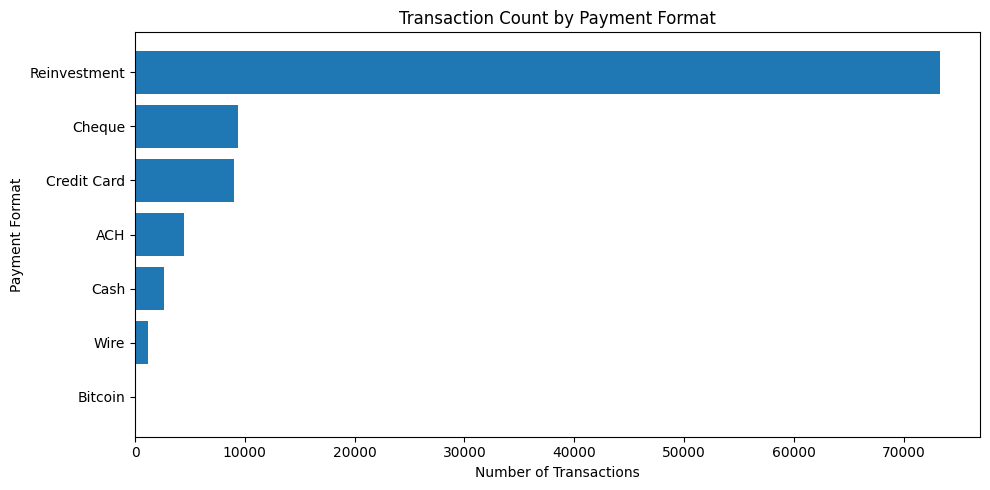

In [ ]:
import matplotlib.pyplot as plt

# Count transactions by payment format
payment_counts = df_eda["Payment Format"].value_counts()

# Create horizontal bar chart
plt.figure(figsize=(10, 5))

plt.barh(
    payment_counts.index,
    payment_counts.values
)

plt.xlabel("Number of Transactions")
plt.ylabel("Payment Format")
plt.title("Transaction Count by Payment Format")

# Display the largest category at the top
plt.gca().invert_yaxis() #show the highest payment format at the top 

plt.tight_layout()
plt.show()


#### Visualization Findings

- **Result:** Reinvestment accounted for 73.30% of all transactions, making it the most frequently recorded payment format.
- **Observation:** Reinvestment had approximately 7.8 times as many transactions as Cheque, the second most common payment method.
- **Impact:** The sample is heavily concentrated in Reinvestment transactions, potentially influencing overall transaction patterns.
- **Limitation:** The findings are based on the first 100,000 records and may not represent the entire dataset.


### 3. Transaction Volume Analysis

**Objective:** Analyze how transaction volume changes over time and identify periods with higher or lower transaction activity.

**Method:** Group transactions by minute, calculate transaction counts, and visualize trends using a line chart.

**Scope:** The first 100,000 transactions, recorded between 00:00 and 00:29 on September 1, 2022.


In [ ]:
# Group transactions by minute
transactions_per_minute = (
    df_eda.groupby(
        df_eda["Timestamp"].dt.floor("min")
    )
    .size()
    .sort_index()
)

# Display transaction counts
display(transactions_per_minute.head(30))

# Calculate summary statistics
avg_transactions = transactions_per_minute.mean()
max_transactions = transactions_per_minute.max()
min_transactions = transactions_per_minute.min()

print(f"Average Transactions per Minute: {avg_transactions:,.2f}")
print(f"Maximum Transactions per Minute: {max_transactions:,}")
print(f"Minimum Transactions per Minute: {min_transactions:,}")


Timestamp
2022-09-01 00:00:00    3355
2022-09-01 00:01:00    3298
2022-09-01 00:02:00    3271
2022-09-01 00:03:00    3320
2022-09-01 00:04:00    3454
2022-09-01 00:05:00    3381
2022-09-01 00:06:00    3305
2022-09-01 00:07:00    3241
2022-09-01 00:08:00    3212
2022-09-01 00:09:00    3261
2022-09-01 00:10:00    3296
2022-09-01 00:11:00    3360
2022-09-01 00:12:00    3384
2022-09-01 00:13:00    3319
2022-09-01 00:14:00    3388
2022-09-01 00:15:00    3259
2022-09-01 00:16:00    3254
2022-09-01 00:17:00    3352
2022-09-01 00:18:00    3307
2022-09-01 00:19:00    3455
2022-09-01 00:20:00    3297
2022-09-01 00:21:00    3494
2022-09-01 00:22:00    3293
2022-09-01 00:23:00    3373
2022-09-01 00:24:00    3326
2022-09-01 00:25:00    3371
2022-09-01 00:26:00    3407
2022-09-01 00:27:00    3302
2022-09-01 00:28:00    3392
2022-09-01 00:29:00    3273
dtype: int64

Average Transactions per Minute: 3,333.33
Maximum Transactions per Minute: 3,494
Minimum Transactions per Minute: 3,212


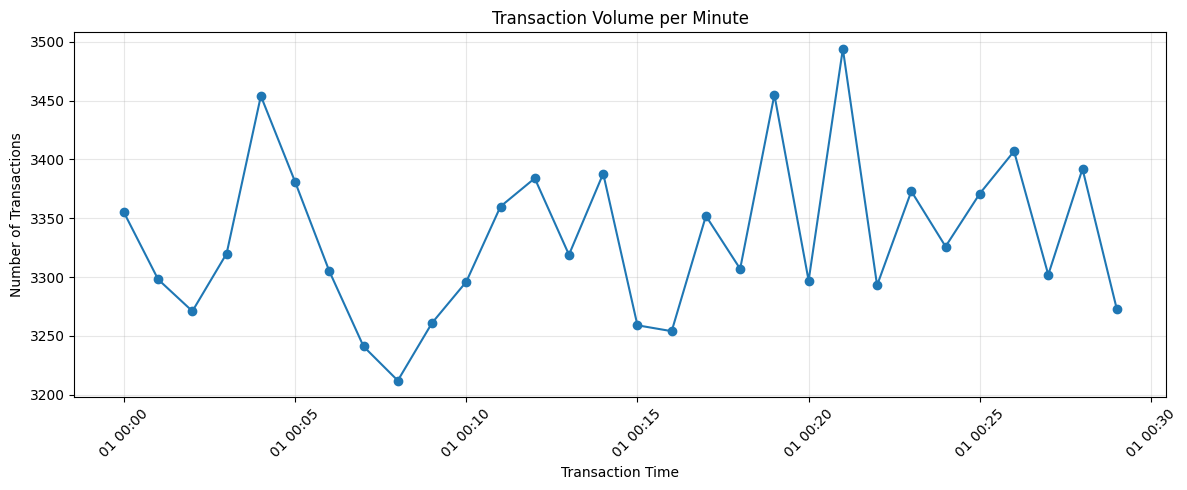

In [ ]:
import matplotlib.pyplot as plt

# Visualize transaction volume over time
plt.figure(figsize=(12, 5))

plt.plot(
    transactions_per_minute.index,
    transactions_per_minute.values,
    marker="o"
)

plt.title("Transaction Volume per Minute")
plt.xlabel("Transaction Time")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


#### Findings

- **Result:** The sample recorded an average of approximately 3,333 transactions per minute.
- **Peak Activity:** The highest transaction count was 3,494 at 00:21, while the lowest was 3,212 at 00:08.
- **Observation:** Transaction counts fluctuated moderately, with no clear increasing or decreasing trend during the observed period.
- **Impact:** The sample shows relatively consistent transaction counts across the 30-minute window.
- **Limitation:** The analysis includes only the first 100,000 records and does not represent the complete transaction activity of the banking system.


### 4. Bank-to-Bank Transaction Analysis

**Objective:** Identify the most active sending and receiving banks based on transaction counts.

**Method:** Count transactions by sending and receiving bank, rank the top banks, and compare their transaction activity.

**Scope:** The first 100,000 transaction records.


In [ ]:

# Count transactions by sending bank
sending_bank_counts = (
    df_eda["From Bank"]
    .value_counts()
    .head(10)
)

print("Top 10 Sending Banks:")
display(sending_bank_counts)


Top 10 Sending Banks:


From Bank
10      2116
1       1989
70      1924
12       993
220      941
1292     876
1362     854
1420     785
513      750
1601     745
Name: count, dtype: int64

In [ ]:

# Count transactions by receiving bank
receiving_bank_counts = (
    df_eda["To Bank"]
    .value_counts()
    .head(10)
)

print("Top 10 Receiving Banks:")
display(receiving_bank_counts)


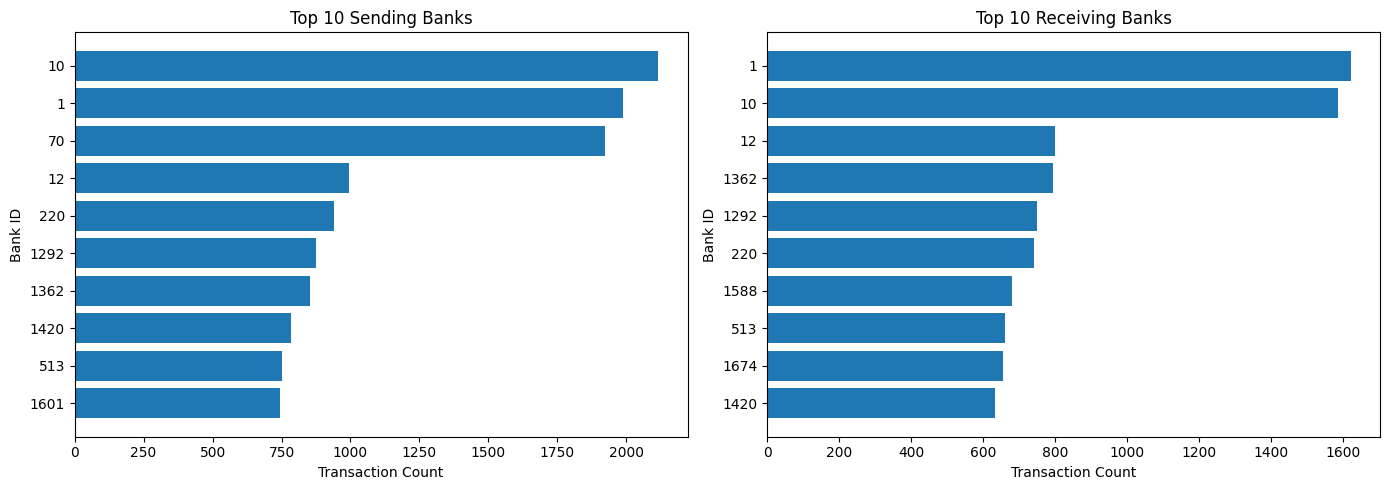

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top sending banks
axes[0].barh(
    sending_bank_counts.index.astype(str),
    sending_bank_counts.values
)
axes[0].invert_yaxis()
axes[0].set_title("Top 10 Sending Banks")
axes[0].set_xlabel("Transaction Count")
axes[0].set_ylabel("Bank ID")

# Top receiving banks
axes[1].barh(
    receiving_bank_counts.index.astype(str),
    receiving_bank_counts.values
)
axes[1].invert_yaxis()
axes[1].set_title("Top 10 Receiving Banks")
axes[1].set_xlabel("Transaction Count")
axes[1].set_ylabel("Bank ID")

plt.tight_layout()
plt.show()


#### Findings

- **Result:** Bank 10 recorded the highest number of outgoing transactions, while Bank 1 had the highest number of incoming transactions.
- **Observation:** Eight banks appeared in both the top 10 sending and receiving rankings, indicating substantial overlap between the two groups.
- **Impact:** Several banks demonstrate relatively high transaction activity in both sending and receiving roles.
- **Limitation:** The analysis is based on transaction counts from the first 100,000 records, rather than transaction values or the full dataset.


### 5. Money Laundering Label Analysis

**Objective:** Examine the distribution of money laundering labels and identify potential differences across payment formats.

**Method:** Calculate the count and percentage of labelled transactions, then compare the laundering label rate across payment methods.

**Scope:** The first 100,000 transaction records.


In [ ]:

# Count transactions by laundering label
laundering_counts = df_eda["Is Laundering"].value_counts()

# Calculate percentage distribution
laundering_percentage = (
    df_eda["Is Laundering"].value_counts(normalize=True) * 100
)

# Create summary table
laundering_summary = pd.DataFrame({
    "Transaction Count": laundering_counts,
    "Percentage (%)": laundering_percentage.round(2)
})

display(laundering_summary)


,Transaction Count,Percentage (%)
Is Laundering,,
0,99995,100.0
1,5,0.0


In [ ]:

# Calculate laundering labels by payment format
laundering_by_format = (
    df_eda.groupby("Payment Format")
    .agg(
        Total_Transactions=("Is Laundering", "count"),
        Labelled_Transactions=("Is Laundering", "sum")
    )
)

# Calculate laundering label rate
laundering_by_format["Label_Rate (%)"] = (
    laundering_by_format["Labelled_Transactions"]
    / laundering_by_format["Total_Transactions"] * 100
)

# Sort payment formats by label rate
laundering_by_format = laundering_by_format.sort_values(
    "Label_Rate (%)",
    ascending=False
)

display(laundering_by_format)


,Total_Transactions,Labelled_Transactions,Label_Rate (%)
Payment Format,,,
Cash,2668,1,0.037481
Credit Card,9028,2,0.022153
Cheque,9393,2,0.021292
Bitcoin,30,0,0.000000
ACH,4436,0,0.000000
Reinvestment,73296,0,0.000000
Wire,1149,0,0.000000


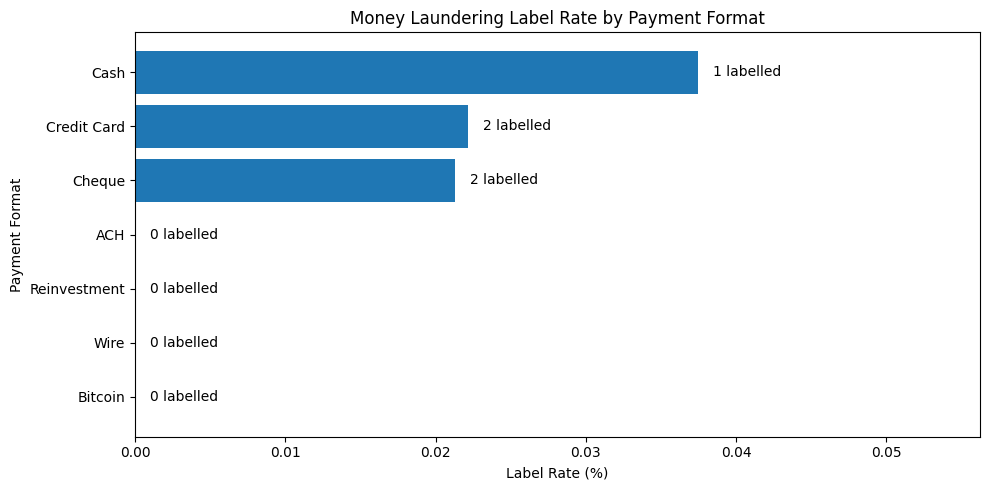

In [ ]:

import matplotlib.pyplot as plt

# Prepare data for visualization
plot_data = laundering_by_format.sort_values(
    "Label_Rate (%)",
    ascending=True
)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_data.index,
    plot_data["Label_Rate (%)"]
)

# Add labelled transaction counts beside each bar
for bar, count in zip(
    bars,
    plot_data["Labelled_Transactions"]
):
    ax.text(
        bar.get_width() + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f"{count} labelled",
        va="center"
    )

# Format chart
ax.set_title("Money Laundering Label Rate by Payment Format")
ax.set_xlabel("Label Rate (%)")
ax.set_ylabel("Payment Format")

ax.set_xlim(0, plot_data["Label_Rate (%)"].max() * 1.5)

plt.tight_layout()
plt.show()



#### Findings

- **Result:** Only 5 out of 100,000 transactions (0.005%) were labelled as money laundering.
- **Observation:** Cash had the highest label rate (0.0375%), followed by Credit Card (0.0222%) and Cheque (0.0213%).
- **Class Imbalance:** The dataset is highly imbalanced, with very few transactions labelled as money laundering.
- **Impact:** The extremely low number of labelled transactions limits the reliability of risk comparisons across payment formats.
- **Limitation:** Findings are based on the first 100,000 synthetic transaction records.



## 6. Executive Summary

### Project Overview

This analysis examined the first 100,000 records from the
IBM Synthetic Financial Transactions dataset to explore
transaction activity, payment methods, participating banks,
and money laundering labels.

### Key Findings

**1. Payment Method Distribution**
- Reinvestment accounted for 73.30% of transactions.
- Cheque (9.39%) and Credit Card (9.03%) were the
  second and third most common payment formats.

**2. Transaction Volume**
- The sample recorded approximately 3,333 transactions
  per minute.
- Transaction counts fluctuated without a clear
  increasing or decreasing trend during the 30-minute
  observation period.

**3. Banking Activity**
- Bank 10 recorded the highest number of outgoing
  transactions.
- Bank 1 recorded the highest number of incoming
  transactions.
- Eight banks appeared in both top 10 rankings.

**4. Money Laundering Labels**
- Only 5 transactions (0.005%) were labelled as
  money laundering.
- Cash had the highest observed label rate (0.0375%),
  although this represented only one labelled transaction.
- The extremely small number of positive labels limits
  meaningful risk comparisons.

### Business Recommendations

1. Investigate transaction patterns using a larger and
   more representative dataset.
2. Examine why Reinvestment represents such a large
   proportion of recorded transactions.
3. Review high-value transactions within comparable
   payment methods and currencies.
4. Avoid making risk decisions based solely on the
   small number of observed laundering labels.

### Limitations

- The analysis uses only the first 100,000 synthetic
  transaction records.
- The sample covers September 1, 2022, from
  00:00 to 00:29.
- Results may not represent broader banking activity
  or real-world money laundering risks.
